# Chapter 5: Pretraining on unlabeled data
This chapter covers the training and evaluation of a GPT model. It also looks at loading pretrained weights from OpenAI

### 5.1 Evaluating Generative Text Models
This chapter looks at how we can evaluate text generartion models

In [1]:
import tiktoken
import sys
sys.path.append("..")
from src.classes import *

In [2]:
%load_ext autoreload
%autoreload 2

In [3]:
GPT_CONFIG_124M = {
    'vocab_size': 50257,
    'context_length': 256,
    'emb_dim': 768,
    'n_heads': 12,
    'n_layers': 12,
    'drop_rate_embedding': 0.1,
    'drop_rate_shortcut': 0.1,
    'drop_rate_multihead': 0.1,
    'qkv_bias': False,
    }

def generate_text_simple(model, idx, max_new_tokens, context_size):
    for _ in range(max_new_tokens):
        idx_cond = idx[:, -context_size:]
        with torch.no_grad():
            logits = model(idx_cond)
        logits = logits[:, -1, :] # Focus only on last timestep, so that (batch, n_token, vocab_size) -> (batch, vocab_size)
        probas = torch.softmax(logits, dim=-1) # Probabilities for token being a word in vocab
        idx_next = torch.argmax(probas, dim=-1, keepdim=True) # Find token with highest probability
        idx = torch.cat((idx, idx_next), dim=1) # Add token at last place in sequence for next prediction

    return idx

In [5]:
torch.manual_seed(123)
model = GPTModel(GPT_CONFIG_124M)
model.eval()
print("Model loaded")

Model loaded


In [6]:
# Create functions for encoding and decoding
def text_to_token_ids(text, tokenizer):
    encoded = tokenizer.encode(text, allowed_special={'<|endoftext|>'})
    encoded_tensor = torch.tensor(encoded).unsqueeze(0) # Adds batch dimension to tensor
    return encoded_tensor

def token_ids_to_text(token_ids, tokenizer):
    flat = token_ids.squeeze(0) # Remove batch dimension
    return tokenizer.decode(flat.tolist())


In [7]:
start_context = "Every effort moves you"
tokenizer = tiktoken.get_encoding("gpt2")

token_ids = generate_text_simple(
    model=model,
    idx=text_to_token_ids(start_context, tokenizer),
    max_new_tokens=10,
    context_size=GPT_CONFIG_124M["context_length"]
    )

print("Output text:\n", token_ids_to_text(token_ids, tokenizer))

Output text:
 Every effort moves you rentingetic wasnم refres RexMeCHicular stren


#### 5.1.2 Calculating the Text Generation Loss
Since we haven't trained the model yet it clearly fails to output coherent text. For training it we need to measure the text generation loss, to see how the model behaves during training and if it's learning anything.

In [8]:
inputs = torch.tensor([[16833, 3626, 6100],  # ["every effort moves",
                       [40, 1107, 588]])     # "I really like"]

targets = torch.tensor([[3626, 6100, 345 ],  # [" effort moves you",
                        [1107, 588, 11311]]) # " really like chocolate"]

with torch.no_grad(): # Feed input into model to calculate logits
    logits = model(inputs)

probas = torch.softmax(logits, dim=-1) # Probability of each token in vocab
print(probas.shape)
token_ids = torch.argmax(probas, dim=-1, keepdim=True) # Get tokenID for higest scoring probability
print("Token IDs:\n", token_ids)

# Convert back into text
print(f"Targets batch 1: {token_ids_to_text(targets[0], tokenizer)}")
print(f"Outputs batch 1:"
 f" {token_ids_to_text(token_ids[0].flatten(), tokenizer)}")

torch.Size([2, 3, 50257])
Token IDs:
 tensor([[[16657],
         [  339],
         [42826]],

        [[49906],
         [29669],
         [41751]]])
Targets batch 1:  effort moves you
Outputs batch 1:  Armed heNetflix


In [9]:
# Initial softmax scores for target tokens
text_idx = 0
target_probas_1 = probas[text_idx, [0, 1, 2], targets[text_idx]]
print("Text 1:", target_probas_1)

text_idx = 1
target_probas_2 = probas[text_idx, [0, 1, 2], targets[text_idx]]
print("Text 2:", target_probas_2)

Text 1: tensor([7.4514e-05, 3.1054e-05, 1.1567e-05])
Text 2: tensor([1.0343e-05, 5.6737e-05, 4.7620e-06])


In [10]:
log_probas = torch.log(torch.cat((target_probas_1, target_probas_2)))
print(log_probas)
avg_log_probas = torch.mean(log_probas)
print("Avergare loss score:", avg_log_probas)
neg_avg_log_probas = avg_log_probas * -1
print("Cross entropy loss", neg_avg_log_probas)

# Cross entropy measures the difference between two probability distributions, typically true distributions (tokens in dataset) vs predicted distribution.

tensor([ -9.5045, -10.3798, -11.3674, -11.4792,  -9.7771, -12.2549])
Avergare loss score: tensor(-10.7938)
Cross entropy loss tensor(10.7938)


In [11]:
print("Logits shape:", logits.shape)        # (batch, num_tokens, vocab_size)
print("Targets shape:", targets.shape)      # (batch, num_tokens)

Logits shape: torch.Size([2, 3, 50257])
Targets shape: torch.Size([2, 3])


In [12]:
# Since the logits and targets have different dimensions we need to flatten them over the batch dimension
logits_flat = logits.flatten(0, 1)
targets_flat = targets.flatten()
print("Flattened logits:", logits_flat.shape)
print("Flattened targets:", targets_flat.shape)

Flattened logits: torch.Size([6, 50257])
Flattened targets: torch.Size([6])


In [13]:
# Calculate cross entropy loss using Pytorch function
loss = torch.nn.functional.cross_entropy(logits_flat, targets_flat)
print(loss)

tensor(10.7938)


In [ ]:
"""
Another measurement commonly used for measuring performance in language models is Perplexity. 
Perplexity measures how well the probability distribution predicted by the model matches the actual distribution of words in the datset.
It can be calculated using: perplexity = torch.exp(loss)
"""

#### 5.1.3 Calculating the Training and Validation set Losses

In [ ]:
file_path = "the-verdict.txt"
with open(file_path, "r", encoding="utf-8") as f:
    text_data = f.read()

In [16]:
total_characters = len(text_data)
total_tokens = len(tokenizer.encode(text_data))
print(f"Total amount of characters: {total_characters}")
print(f"Total amount of tokens: {total_tokens}")

Total amount of characters: 20479
Total amount of tokens: 5145


In [17]:
# Split data into training and validation sets
train_ratio = 0.9
split_idx   = int(train_ratio * len(text_data))
train_data  = text_data[:split_idx]
val_data    = text_data[split_idx:]

In [18]:
# Dataloader from chapter 2
from torch.utils.data import DataLoader
from src.classes import GPTDatasetV1


def create_dataloader_v1(txt, batch_size=4, max_length=256, stride=128,
                        shuffle=True, drop_last=True, num_workers=0):
    """Function that uses GPTDatasetV1 to load the inputs in batches via a Pytorch DataLoader"""
    tokenizer = tiktoken.get_encoding("gpt2") # Initialize tokenizer

    # Create dataset
    dataset = GPTDatasetV1(txt, tokenizer, max_length, stride)

    # Create dataloader
    dataloader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle,
        drop_last=drop_last,
        num_workers=num_workers
    )

    return dataloader

In [19]:
torch.manual_seed(123)

train_loader = create_dataloader_v1(
    train_data,
    batch_size=2,
    max_length=GPT_CONFIG_124M["context_length"],
    stride=GPT_CONFIG_124M["context_length"],
    drop_last=True,
    shuffle=True,
    num_workers=0
)

val_loader = create_dataloader_v1(
    val_data,
    batch_size=2,
    max_length=GPT_CONFIG_124M["context_length"],
    stride=GPT_CONFIG_124M["context_length"],
    drop_last=False,
    shuffle=False,
    num_workers=0
)

In [20]:
print("Train loader:")
for x,y in train_loader:
    print(x.shape, y.shape)

print("\nValidation loader:")
for x,y in val_loader:
    print(x.shape, y.shape)

Train loader:
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])

Validation loader:
torch.Size([2, 256]) torch.Size([2, 256])


In [21]:
def calc_loss_batch(input_batch, target_batch, model, device):
    """Function that calclulates cross entropy loss of a given batch"""
    input_batch  = input_batch.to(device) # So we can use GPU for calculations
    target_batch = target_batch.to(device)

    logits = model(input_batch)
    loss   = torch.nn.functional.cross_entropy(
        logits.flatten(0, 1), target_batch.flatten()
    )
    return loss

def calc_loss_loader(data_loader, model, device, num_batches=None):
    """Function that calclulates average cross entropy loss over all batches"""
    total_loss = 0

    if len(data_loader) == 0:
        return float("nan")
    elif num_batches is None:
        num_batches = len(data_loader) # Iterates over all batches if not specified
    else:
        num_batches = min(num_batches, len(data_loader)) # Reduces the number of batches to match the total number of batches in loader (i.e. can't have a number > number of batches)

    for i, (input_batch, target_batch) in enumerate(data_loader):
        if i < num_batches:
            loss = calc_loss_batch(input_batch, target_batch, model, device)
            total_loss += loss.item()
        else:
            break
    return total_loss / num_batches

In [22]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu") # Use GPU if possible
model.to(device)
with torch.no_grad():
    train_loss  = calc_loss_loader(train_loader, model, device)
    val_loss    = calc_loss_loader(val_loader, model, device)

print(f"Training loss: {train_loss:3f} and validation loss: {val_loss:3f}")

Training loss: 10.987385 and validation loss: 10.980906


### 5.2 Trainin an LLM
Now that the loss functions are created we can start training the model.

In [23]:
# Simple training function

def train_model_simple(model, train_loader, val_loader, optimizer, device, num_epochs, eval_freq, eval_iter, start_context, tokenizer):
    train_losses, val_losses, track_tokens_seen = [], [], []
    tokens_seen, global_step = 0, -1

    for epoch in range(num_epochs):
        model.train()                   # set to train so that we can update weights

        for input_batch, target_batch in train_loader:
            optimizer.zero_grad()       # Resets loss gradients from the previous batch iteration
            loss = calc_loss_batch(input_batch, target_batch, model, device)
            loss.backward()             # Calculate loss gradients
            optimizer.step()            # Update model weights using loss gradients
            tokens_seen += input_batch.numel()
            global_step += 1

            if global_step % eval_freq == 0:
                train_loss, val_loss = evaluate_model(
                    model, train_loader, val_loader, device, eval_iter
                )
                train_losses.append(train_loss)
                val_losses.append(val_loss)
                track_tokens_seen.append(tokens_seen)
                print(f"Ep {epoch+1} (Step {global_step:06d}): "
                    f"Train loss {train_loss:.3f}, "
                    f"Val loss {val_loss:.3f}")

        generate_and_print_sample(model, tokenizer, device, start_context)

    return train_losses, val_losses, track_tokens_seen

def evaluate_model(model, train_loader, val_loader, device, eval_iter):
    """Function that evaluates the model on the validation set"""
    model.eval()        # Set model to eval mode to not update parameters

    with torch.no_grad():
        train_loss  = calc_loss_loader(train_loader, model, device, num_batches=eval_iter)
        val_loss    = calc_loss_loader(val_loader, model, device, num_batches=eval_iter)
    model.train()       # Set model to train mode again 
    return train_loss, val_loss

def generate_and_print_sample(model, tokenizer, device, start_context):
    """Function that is used to generate and print some text for tracking if model improves during training."""
    model.eval()
    context_size = model.pos_emb.weight.shape[0]
    encoded      = text_to_token_ids(start_context, tokenizer).to(device)
    with torch.no_grad():
        token_ids = generate_text_simple(model=model, idx=encoded, max_new_tokens=50, context_size=context_size)
    decoded_text = token_ids_to_text(token_ids, tokenizer)
    print(decoded_text.replace("\n", " "))
    model.train()

In [24]:
# Train using AdamW optimizer
torch.manual_seed(123)
model = GPTModel(GPT_CONFIG_124M)
model.to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=0.0004, weight_decay=0.1)

num_epochs = 10
train_losses, val_losses, tokens_seen = train_model_simple(
    model, train_loader, val_loader, optimizer, device, num_epochs=num_epochs, eval_freq=5,
    eval_iter=5, start_context="Every effort moves you", tokenizer=tokenizer
)

Ep 1 (Step 000000): Train loss 9.821, Val loss 9.928
Ep 1 (Step 000005): Train loss 8.067, Val loss 8.339
Every effort moves you,,,,,,,,,,,,.                                     
Ep 2 (Step 000010): Train loss 6.625, Val loss 7.051
Ep 2 (Step 000015): Train loss 6.049, Val loss 6.603
Every effort moves you, and,, and,,,,,,, and,.                                   
Ep 3 (Step 000020): Train loss 5.560, Val loss 6.494
Ep 3 (Step 000025): Train loss 5.431, Val loss 6.385
Every effort moves you, and to the to the of the to the, and I had. Gis, and, and, and, and, and, and I had, and, and, and, and, and, and, and, and, and,
Ep 4 (Step 000030): Train loss 4.978, Val loss 6.286
Ep 4 (Step 000035): Train loss 4.723, Val loss 6.300
Every effort moves you of the picture.      "I                "I"I the picture"I had the picture"I the picture and I had been the picture of
Ep 5 (Step 000040): Train loss 4.066, Val loss 6.159
Every effort moves you know the                                          

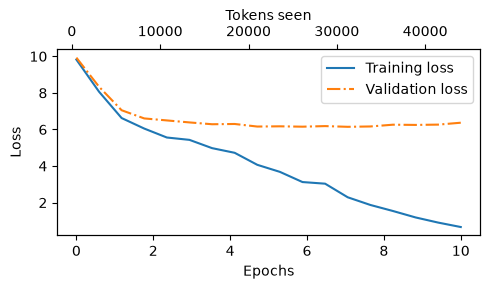

In [25]:
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
def plot_losses(epochs_seen, tokens_seen, train_losses, val_losses):
 fig, ax1 = plt.subplots(figsize=(5, 3))
 ax1.plot(epochs_seen, train_losses, label="Training loss")
 ax1.plot(
 epochs_seen, val_losses, linestyle="-.", label="Validation loss"
 )
 ax1.set_xlabel("Epochs")
 ax1.set_ylabel("Loss")
 ax1.legend(loc="upper right")
 ax1.xaxis.set_major_locator(MaxNLocator(integer=True))
 ax2 = ax1.twiny()
 ax2.plot(tokens_seen, train_losses, alpha=0)
 ax2.set_xlabel("Tokens seen")
 fig.tight_layout()
 plt.show()
epochs_tensor = torch.linspace(0, num_epochs, len(train_losses))
plot_losses(epochs_tensor, tokens_seen, train_losses, val_losses)

In [ ]:
# From the plot we can see that the model is overfitting and memorizing the training data. Not unsurprising since small dataset and multiple epochs

### 5.3 Decoding Strategies to Control Randomness
Some strategies to generate more original text

In [26]:
model.to("cpu")
model.eval()
tokenizer = tiktoken.get_encoding("gpt2")
token_ids = generate_text_simple(
    model=model,
    idx=text_to_token_ids("Every effort moves you", tokenizer),
    max_new_tokens=25,
    context_size=GPT_CONFIG_124M["context_length"]
)
print("Output text:\n", token_ids_to_text(token_ids, tokenizer))

Output text:
 Every effort moves you?"

"Yes--quite insensible to the irony. She wanted him vindicated--and by me!"




#### 5.3.1 Temperature Scaling
Right now the generated token is selected at each generation step corresponfing to the highest probability. So, every time text is generated it will be the same. To fix this we can add a probabilistic selection process e.g. temperature scaling

In [29]:
# Illustrating probabilistic sampling, assuming start text is "Every effort moves you"
vocab = {
 "closer": 0,
 "every": 1,
 "effort": 2,
 "forward": 3,
 "inches": 4,
 "moves": 5,
 "pizza": 6,
 "toward": 7,
 "you": 8,
}
inverse_vocab = {v: k for k, v in vocab.items()}

next_token_logits = torch.tensor(
 [4.51, 0.89, -1.90, 6.75, 1.63, -1.62, -1.89, 6.28, 1.79]
)

In [30]:
probas = torch.softmax(next_token_logits, dim=0)
next_token_id = torch.argmax(probas).item()
print(inverse_vocab[next_token_id])

# using argmax always results in forward being the highest probable token (6.75 is the highest score in the tensor)

forward


In [31]:
# By changing argmax to multinomal we can implement probalistic sampling
torch.manual_seed(123)
next_token_id = torch.multinomial(probas, num_samples=1).item()
print(inverse_vocab[next_token_id])

# Still printing forward most of the time since it still has the highest probability

forward


In [32]:
def print_sampled_tokens(probas):
    torch.manual_seed(123)
    sample = [torch.multinomial(probas, num_samples=1).item() for i in range(1_000)]
    sampled_ids = torch.bincount(torch.tensor(sample)) 
    for i, freq in enumerate(sampled_ids):
        print(f"{freq} x {inverse_vocab[i]}")
print_sampled_tokens(probas)

73 x closer
0 x every
0 x effort
582 x forward
2 x inches
0 x moves
0 x pizza
343 x toward


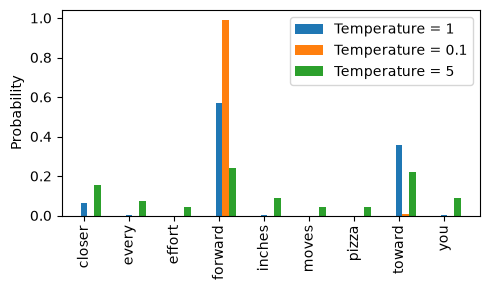

In [33]:
# By running it 1000 times we can see that the model chooses forward only around 58% of the time, and by so we have achieved probabilistic sampling
# By introducing temperature scaling (dividing logits with a number 0 < x) we can increase and lower the probabilistic sampling

def softmax_with_temperature(logits, temperature):
    scaled_logits = logits / temperature
    return torch.softmax(scaled_logits, dim=0)

temperatures = [1, 0.1, 5] # Original, lower and higher temperature
scaled_probas = [softmax_with_temperature(next_token_logits, T) for T in temperatures]

x = torch.arange(len(vocab))
bar_width = 0.15
fig, ax = plt.subplots(figsize=(5, 3))
for i, T in enumerate(temperatures):
    rects = ax.bar(x + i * bar_width, scaled_probas[i], bar_width, label=f"Temperature = {T}")
ax.set_ylabel("Probability")
ax.set_xticks(x)
ax.set_xticklabels(vocab.keys(), rotation=90)
ax.legend()
plt.tight_layout()
plt.show()

# higher temperature = more uniform distribution whilst lower temperature = sharper distribution


In [34]:
# Exercise 5.1
temperatures = [1, 0.1, 5] # Original, lower and higher temperature
scaled_probas = [softmax_with_temperature(next_token_logits, T) for T in temperatures]

for i in range(len(temperatures)):
    print_sampled_tokens(scaled_probas[i])


73 x closer
0 x every
0 x effort
582 x forward
2 x inches
0 x moves
0 x pizza
343 x toward
0 x closer
0 x every
0 x effort
985 x forward
0 x inches
0 x moves
0 x pizza
15 x toward
165 x closer
75 x every
42 x effort
239 x forward
71 x inches
46 x moves
32 x pizza
227 x toward
103 x you


### 5.3.2 Top-k sampling
Now we have added a probabilistic sampling technique that works, but sometimes it results in nonsensical outputs. To reduce this we can add top-k sampling as well, which only keeps the top-k most realistic tokens. 

In [35]:
top_k = 3
top_logits, top_pos = torch.topk(next_token_logits, top_k)
print(f"Top logits: {top_logits}")
print(f"Top positions {top_pos}")

Top logits: tensor([6.7500, 6.2800, 4.5100])
Top positions tensor([3, 7, 0])


In [36]:
# Apply torch.where to asign -inf to the logits which are not the top-k highest scoring ones
new_logits = torch.where(
    condition=next_token_logits < top_logits[-1],
    input=torch.tensor(float("-inf")),
    other=next_token_logits
)
print(new_logits)

tensor([4.5100,   -inf,   -inf, 6.7500,   -inf,   -inf,   -inf, 6.2800,   -inf])


In [37]:
topk_probas = torch.softmax(new_logits, dim=0)
print(topk_probas)

tensor([0.0615, 0.0000, 0.0000, 0.5775, 0.0000, 0.0000, 0.0000, 0.3610, 0.0000])


#### 5.3.3 Modifying the Text Generation Function
Now we add both probabilistic sampling and top-k sampling to out text generation function

In [39]:
def generate(model, idx, max_new_tokens, context_size, temperature=0.0, top_k=None, eos_id=None):

    if eos_id is not None and idx.shape[0] != 1:
        raise ValueError("EOS stopping currently supports batch size 1 only")

    # For-loop is the same as before: Get logits, and only focus on last time step
    for _ in range(max_new_tokens):
        idx_cond = idx[:, -context_size:]
        with torch.no_grad():
            logits = model(idx_cond)
        logits = logits[:, -1, :]

        # New: Filter logits with top_k sampling
        if top_k is not None:
            # Keep only top_k values
            top_logits, _ = torch.topk(logits, top_k)
            min_val = top_logits[:, -1]
            logits = torch.where(logits < min_val, torch.tensor(float("-inf")).to(logits.device), logits)

        # New: Apply temperature scaling
        if temperature > 0.0:
            logits = logits / temperature

            # New (not in book): numerical stability tip to get equivalent results on mps device
            # subtract rowwise max before softmax
            logits = logits - logits.max(dim=-1, keepdim=True).values

            # Apply softmax to get probabilities
            probs = torch.softmax(logits, dim=-1)  # (batch_size, context_len)

            # Sample from the distribution
            idx_next = torch.multinomial(probs, num_samples=1)  # (batch_size, 1)

        # Otherwise same as before: get idx of the vocab entry with the highest logits value
        else:
            idx_next = torch.argmax(logits, dim=-1, keepdim=True)  # (batch_size, 1)

        if idx_next == eos_id:  # Stop generating early if end-of-sequence token is encountered and eos_id is specified
            break

        # Same as before: append sampled index to the running sequence
        idx = torch.cat((idx, idx_next), dim=1)  # (batch_size, num_tokens+1)

    return idx

In [43]:
torch.manual_seed(123)
token_ids = generate(
 model=model,
 idx=text_to_token_ids("Every effort moves you", tokenizer),
 max_new_tokens=15,
 context_size=GPT_CONFIG_124M["context_length"],
 top_k=3,
 temperature=0.7
)
a = token_ids_to_text(token_ids, tokenizer)
print(f"Output text:\n{a}")

Output text:
Every effort moves you?"

"Yes--quite insensible to the fact with his last


In [ ]:

"""
Exercise 5.2: Low temperature and top-k is desired when we want the answer to be more precise e.g. in the medical field where it's important that the answer is correct.
High temperature and top-k is better when writing e.g. stories and we need more fantasy ot doing other forms of creative work.

Exercise 5.3: Turning of temperature (top-k can be whatever) or setting top-k to one will result in the same results as the previous generate function.
"""

### 5.4 Loading and Saving Model Weights in PyTorch
When training is finishid it's important to save the weights so they can be loaded and used again later on without having to retrain the model. 

In [44]:
torch.save(model.state_dict(), "model.pth")

In [46]:
# Loading the weights
model = GPTModel(GPT_CONFIG_124M)
model.load_state_dict(torch.load("model.pth", map_location=device))
model.eval() # During inference we don't want to randomly drop information the model has learned
print("Model loaded successfully")

Model loaded successfully


In [47]:
# If we plan on continue training later it's important to load other things as well, e.g. the AdamW optimizer which has adaptive parameters
torch.save({
    "model_state_dict": model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    }, 
    "model_and_optimizer.pth"
    )

In [49]:
# Load both model and optimizer parameters
checkpoint = torch.load("model_and_optimizer.pth", map_location=device)
model = GPTModel(GPT_CONFIG_124M)
model.load_state_dict(checkpoint["model_state_dict"])
optimizer = torch.optim.AdamW(model.parameters(), lr=5e-4, weight_decay=0.1)
optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
model.train()
print("Model loaded successfully")

Model loaded successfully


### Loading Weights from OpenAI
Now that we know how to save and load local parameters, let's look at loading open parameters from companies such as OpenAI

In [50]:
import urllib.request
url = (
 "https://raw.githubusercontent.com/rasbt/"
 "LLMs-from-scratch/main/ch05/"
 "01_main-chapter-code/gpt_download.py"
)
filename = url.split('/')[-1]
urllib.request.urlretrieve(url, filename)

('gpt_download.py', <http.client.HTTPMessage at 0x226cf0bac60>)

In [52]:
from gpt_download import download_and_load_gpt2

In [53]:
settings, params = download_and_load_gpt2(model_size="124M", models_dir="gpt2")

checkpoint: 100%|██████████| 77.0/77.0 [00:00<00:00, 77.0kiB/s]
encoder.json: 100%|██████████| 1.04M/1.04M [00:00<00:00, 1.46MiB/s]
hparams.json: 100%|██████████| 90.0/90.0 [00:00<00:00, 90.0kiB/s]
model.ckpt.data-00000-of-00001: 100%|██████████| 498M/498M [03:23<00:00, 2.45MiB/s] 
model.ckpt.index: 100%|██████████| 5.21k/5.21k [00:00<00:00, 2.61MiB/s]
model.ckpt.meta: 100%|██████████| 471k/471k [00:00<00:00, 856kiB/s] 
vocab.bpe: 100%|██████████| 456k/456k [00:00<00:00, 946kiB/s] 


In [54]:
print("Settings:", settings)
print("Parameter dictionary keys:", params.keys())

Settings: {'n_vocab': 50257, 'n_ctx': 1024, 'n_embd': 768, 'n_head': 12, 'n_layer': 12}
Parameter dictionary keys: dict_keys(['blocks', 'b', 'g', 'wpe', 'wte'])


In [56]:
print(params["wte"])
print("Token embedding weight tensor dimensions: ", params["wte"].shape)

[[-0.11010301 -0.03926672  0.03310751 ... -0.1363697   0.01506208
   0.04531523]
 [ 0.04034033 -0.04861503  0.04624869 ...  0.08605453  0.00253983
   0.04318958]
 [-0.12746179  0.04793796  0.18410145 ...  0.08991534 -0.12972379
  -0.08785918]
 ...
 [-0.04453601 -0.05483596  0.01225674 ...  0.10435229  0.09783269
  -0.06952604]
 [ 0.1860082   0.01665728  0.04611587 ... -0.09625227  0.07847701
  -0.02245961]
 [ 0.05135201 -0.02768905  0.0499369  ...  0.00704835  0.15519823
   0.12067825]]
Token embedding weight tensor dimensions:  (50257, 768)


In [55]:
# The GPT2 has different size models that we can load the weights and parameters from
model_configs = {
 "gpt2-small (124M)": {"emb_dim": 768, "n_layers": 12, "n_heads": 12},
 "gpt2-medium (355M)": {"emb_dim": 1024, "n_layers": 24, "n_heads": 16},
 "gpt2-large (774M)": {"emb_dim": 1280, "n_layers": 36, "n_heads": 20},
 "gpt2-xl (1558M)": {"emb_dim": 1600, "n_layers": 48, "n_heads": 25},
}

In [57]:
# We can update our model config using the gpt2-small parameters
model_name = "gpt2-small (124M)"
NEW_CONFIG = GPT_CONFIG_124M.copy()
NEW_CONFIG.update(model_configs[model_name])

In [58]:
NEW_CONFIG.update({"context_length": 1024}) # Update context length to match downloaded model
NEW_CONFIG.update({"qkv_bias": True}) # Turn on qkv bias
"""Bias vector are not commonly used anymore since they don't improve performance, however they're needed here since the orignal GPT2 model uses them"""

"Bias vector are not commonly used anymore since they don't improve performance, however they're needed here since the orignal GPT2 model uses them"

In [60]:
gpt = GPTModel(NEW_CONFIG)
gpt.eval()
print("Model loaded successfully")

Model loaded successfully


In [61]:
def assign(left, right):
    """Function that checks whether two tensor are the same shape, and returns the right tensor as trainable PyTorch parameters"""
    if left.shape != right.shape:
        raise ValueError(f"Shape mismatch. Left: {left.shape}\nRight: {right.shape}")
    return torch.nn.Parameter(torch.tensor(right))

In [62]:
import numpy as np

def load_weights_into_gpt(gpt, params):
    gpt.pos_emb.weight = assign(gpt.pos_emb.weight, params["wpe"]) # Set positional and token embedding weights to those in parameters
    gpt.tok_emb.weight = assign(gpt.tok_emb.weight, params["wte"])

    for b in range(len(params["blocks"])):
        # Splits attention weights into 3 equal parts; query, key & value
        q_w, k_w, v_w = np.split(       
            (params["blocks"][b]["attn"]["c_attn"])["w"], 3, axis=-1)
        gpt.trf_blocks[b].att.W_query.weight = assign(
            gpt.trf_blocks[b].att.W_query.weight, q_w.T)
        gpt.trf_blocks[b].att.W_key.weight = assign(
            gpt.trf_blocks[b].att.W_key.weight, k_w.T)
        gpt.trf_blocks[b].att.W_value.weight = assign(
            gpt.trf_blocks[b].att.W_value.weight, v_w.T)
        
        # Same but bias part for query, key & value
        q_b, k_b, v_b = np.split(           
            (params["blocks"][b]["attn"]["c_attn"])["b"], 3, axis=-1)
        gpt.trf_blocks[b].att.W_query.bias = assign(
            gpt.trf_blocks[b].att.W_query.bias, q_b)
        gpt.trf_blocks[b].att.W_key.bias = assign(
            gpt.trf_blocks[b].att.W_key.bias, k_b)
        gpt.trf_blocks[b].att.W_value.bias = assign(
            gpt.trf_blocks[b].att.W_value.bias, v_b)

        # Weights and bias for projection layer
        gpt.trf_blocks[b].att.out_proj.weight = assign(
            gpt.trf_blocks[b].att.out_proj.weight,
            params["blocks"][b]["attn"]["c_proj"]["w"].T)
        gpt.trf_blocks[b].att.out_proj.bias = assign(
            gpt.trf_blocks[b].att.out_proj.bias,
            params["blocks"][b]["attn"]["c_proj"]["b"])

        # Weights and bias for both feed forward layers
        gpt.trf_blocks[b].ff.layers[0].weight = assign(
            gpt.trf_blocks[b].ff.layers[0].weight,
            params["blocks"][b]["mlp"]["c_fc"]["w"].T)
        gpt.trf_blocks[b].ff.layers[0].bias = assign(
            gpt.trf_blocks[b].ff.layers[0].bias,
            params["blocks"][b]["mlp"]["c_fc"]["b"])
        gpt.trf_blocks[b].ff.layers[2].weight = assign(
            gpt.trf_blocks[b].ff.layers[2].weight,
            params["blocks"][b]["mlp"]["c_proj"]["w"].T)
        gpt.trf_blocks[b].ff.layers[2].bias = assign(
            gpt.trf_blocks[b].ff.layers[2].bias,
            params["blocks"][b]["mlp"]["c_proj"]["b"])

        # Weights for normalizing layers
        gpt.trf_blocks[b].norm1.scale = assign(
            gpt.trf_blocks[b].norm1.scale,
            params["blocks"][b]["ln_1"]["g"])
        gpt.trf_blocks[b].norm1.shift = assign(
            gpt.trf_blocks[b].norm1.shift,
            params["blocks"][b]["ln_1"]["b"])
        gpt.trf_blocks[b].norm2.scale = assign(
            gpt.trf_blocks[b].norm2.scale,
            params["blocks"][b]["ln_2"]["g"])
        gpt.trf_blocks[b].norm2.shift = assign(
            gpt.trf_blocks[b].norm2.shift,
            params["blocks"][b]["ln_2"]["b"])

    gpt.final_norm.scale = assign(gpt.final_norm.scale, params["g"])
    gpt.final_norm.shift = assign(gpt.final_norm.shift, params["b"])
    gpt.out_head.weight = assign(gpt.out_head.weight, params["wte"]) # Weight tying. I.e. reusing the token embedding weights in the output layer

In [63]:
load_weights_into_gpt(gpt, params)
gpt.to(device)
print("Weights and parameters finished loading")


Weights and parameters finished loading


In [73]:
torch.manual_seed(123)
token_ids = generate(
    model=gpt,
    idx=text_to_token_ids("Every effort moves you", tokenizer).to(device),
    max_new_tokens=25,
    context_size=NEW_CONFIG["context_length"],
    top_k=50,
    temperature=1.5
)
print("Output text:\n", token_ids_to_text(token_ids, tokenizer))

Output text:
 Every effort moves you as far as the hand can go until the end of your turn unless something happens

This would remove you from a battle


### Exercise 5.5 
Calculate training and validation loss using the GPT2 weights

In [66]:
train_loss = calc_loss_loader(train_loader, gpt, device)
val_loss = calc_loss_loader(val_loader, gpt, device)
print(f"Train loss = {train_loss} & validation loss = {val_loss}")

Train loss = 3.7546271483103433 & validation loss = 3.559617042541504
